# NN_L1_logit_coef

**Logistic regression of default on standardised HMEQ variables (with a missing-value indicator for the debt-to-income ratio): coefficients and 95 % confidence intervals.**

Neural Networks and Deep Learning (NN), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L1/NN_L1_logit_coef/NN_L1_logit_coef.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 1 of *Neural Networks and Deep Learning*: the chart `logit_coef` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

odds ratio, debt-to-income missing = 2.89   [logit.or.miss_DEBTINC]
odds ratio, delinquent lines (per sd) = 2.17   [logit.or.DELINQ]
McFadden pseudo-R2 = 0.374   [logit.pseudo_r2]


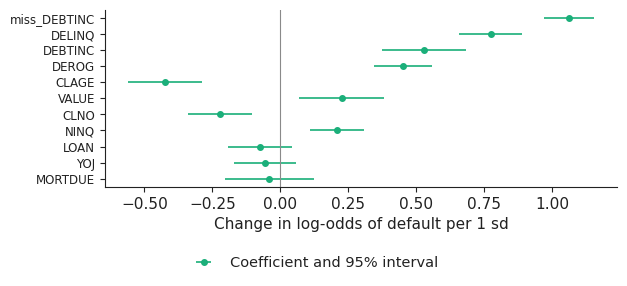

In [3]:
import xgboost as xgb            # import before torch (OpenMP runtimes on macOS)
import torch, torch.nn as nn
torch.set_num_threads(1)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.model_selection import train_test_split, StratifiedKFold
SEED = 20261108

NUM = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
def encode_hmeq(tr, others):
    """median fill + missing indicators + one-hot, fitted on the training part only"""
    med = tr[NUM].median()
    def f(d):
        x = pd.DataFrame(index=d.index)
        for c in NUM:
            x[c] = d[c].fillna(med[c]); x['miss_' + c] = d[c].isna().astype(float)
        for c, lv in (('REASON', ['DebtCon', 'HomeImp']), ('JOB', ['Mgr', 'Office', 'Other', 'ProfExe', 'Sales', 'Self'])):
            for v in lv:
                x[f'{c}_{v}'] = (d[c] == v).astype(float)
        return x
    xtr = f(tr); mu, sd = xtr.mean(), xtr.std().replace(0, 1)
    return [((xtr - mu) / sd).values.astype(np.float32)] + [((f(o) - mu) / sd).values.astype(np.float32) for o in others], list(xtr.columns)

h = pd.read_csv(DATA + 'hmeq.csv'); yh = h.pop('BAD').values.astype(int)
i_tr, i_te = train_test_split(np.arange(len(h)), test_size=0.2, stratify=yh, random_state=SEED)
i_tr, i_va = train_test_split(i_tr, test_size=0.25, stratify=yh[i_tr], random_state=SEED)
(Xtr, Xva, Xte), cols = encode_hmeq(h.iloc[i_tr], [h.iloc[i_va], h.iloc[i_te]])
ytr, yva, yte = yh[i_tr], yh[i_va], yh[i_te]
import statsmodels.api as sm
base = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC', 'miss_DEBTINC']
ci = [cols.index(c) for c in base]
lm = sm.Logit(ytr, sm.add_constant(Xtr[:, ci].astype(float))).fit(disp=0)
coef = pd.DataFrame({'b': lm.params[1:], 'lo': lm.conf_int()[1:, 0], 'hi': lm.conf_int()[1:, 1]}, index=base)
coef = coef.reindex(coef['b'].abs().sort_values().index)
show('logit.or.miss_DEBTINC', 'odds ratio, debt-to-income missing', round(float(np.exp(coef.loc['miss_DEBTINC', 'b'])), 2))
show('logit.or.DELINQ', 'odds ratio, delinquent lines (per sd)', round(float(np.exp(coef.loc['DELINQ', 'b'])), 2))
show('logit.pseudo_r2', 'McFadden pseudo-R2', round(float(lm.prsquared), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.9)); yy = np.arange(len(coef))
ax.errorbar(coef['b'], yy, xerr=[coef['b'] - coef['lo'], coef['hi'] - coef['b']], fmt='o', color=PAL['benchmark'], ms=4, lw=1.2,
            label='Coefficient and 95% interval')
ax.axvline(0, color='#8a8a8a', lw=0.8); ax.set_yticks(yy); ax.set_yticklabels(coef.index, fontsize=8.5)
ax.set_xlabel('Change in log-odds of default per 1 sd')
legend_bottom(fig); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('logit_coef.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()